# Plan 2 · Agentic Vision RAG: demo run with our fine-tuned 7B

> **Demo, not an evaluation.** Every number below comes from this run, and none of them is a result. The VLM's class is compared with the segmenter's class: that is agreement between two models, not accuracy, on 10 tiles. The test against ground truth is Part B.

**Author:** Tamanna (Member B) · **Group:** CSE499B Group 5 · **Folder:** `Essential_task_delegation/Tamanna_task_2/Plan_2/`
**VLM:** `AbrarAlam/disasterm3-qwen2.5vl7b-mergedFP` (our fine-tuned Qwen2.5-VL-7B, merged), 4-bit NF4, greedy decoding.
**Companion notebook:** `BaseModel_and_PaliGemma2_Benchmark.ipynb` runs the same steps on the same 10 tiles with the base Qwen2.5-VL-7B.

## What it does
1. **Tiles:** 10 tiles drawn with seed 42 from the team's validation split, the 645 images R9 never trained on (`train_test_split(pairs, test_size=0.1, random_state=42)`, as in the D4 notebooks). Only colour photos are kept: the image type is read from DisasterM3's list (`post_image_type == "Optical"`), never from file names.
2. **Segmenter:** R9, the D4 champion recipe (U-Net + ResNet-50), loaded strictly from its checkpoint. Images are normalised with ImageNet's mean and std (`A.Normalize`, as in training) and run at full size, padded to a multiple of 32 (the E-protocol).
3. **Crops:** up to 3 buildings per tile, Destroyed and Damaged first, each a 256 × 256 window of the original image.
4. **VLM:** two questions per building. First its damage class on its own, in one word; then a description, an EMS-98 grade and a rescue priority. Both prompts are built for each building, and neither contains the segmenter's class.
5. **Outputs** in `/kaggle/working/plan2_demo/`: `finetuned_demo_tiles.csv`, `finetuned_demo_crops.csv`, `finetuned_demo_summary.csv`, `finetuned_demo_config.json`, `finetuned_demo_dashboard.png` and `finetuned_demo_chart.png`.

## Changed on 27 Oct 2026, after Abrar's review
- No typed-in or fallback numbers. The earlier summary cell typed in results that no run had produced, and fell back to others when a value was missing; the summary and the chart now show only this run's measured values.
- The VLM is no longer told the segmenter's class or asked to agree with it.
- `import re` added: without it the earlier version stopped at the tile selection.
- ImageNet normalisation before the U-Net, as in training (the earlier version divided by 255 and resized to 512).
- Only colour photos, by DisasterM3's list. Four radar tiles had been used: la_palma_volcano_00000560, spain_volcano_00000894, mexico_hurricane_00000018 and spain_volcano_00000028.
- Tiles come from the team's validation split; the earlier split was a different shuffle of file names and included training images.
- R9 is loaded strictly, and the run stops if it can't be found. The earlier run fell back to the B1 baseline (ResNet-34) when R9's private repo refused it.
- Dashboard boxes are drawn in the segmenter's own format, corners (x1, y1, x2, y2).
- PaliGemma is dropped: the edge model is L2's job.
- The earlier outputs were removed. Every output below comes from one Restart & Run All.

## How to run on Kaggle
1. **Settings:** GPU T4, internet on.
2. **Input:** the `abrarmohammedtanzim/disasterm3-mirror` dataset.
3. **R9's checkpoint**, which is private. Either:
   - a Kaggle secret `HF_TOKEN` that can read `AbrarAlam/disasterm3-d4-R9` (Add-ons > Secrets, switched on for this notebook); or
   - the output of Abrar's `d4-champion-model-R9` notebook added as an input (it holds `d4_R9/final_model.pth`), once Abrar shares it.

   Without either, the notebook stops at cell 4 and says which is missing; it never falls back to another model.
4. Restart & Run All, then Save Version, then Save & Run All (Commit).


## 1. Environment

In [1]:
# ── Cell 1: Environment (Kaggle's own torch; the D4 notebooks' pins) ──
import importlib.metadata as _md
import os
import subprocess
import sys

# The outputs must come from one Restart & Run All. A kernel that already ran cells keeps their state (an
# earlier run's model can still be on the GPU and inflate the peak memory), so an interactive run stops here
# unless this is the kernel's first cell. Kaggle's Save & Run All (Commit) always starts a fresh kernel.
if os.environ.get("KAGGLE_KERNEL_RUN_TYPE") != "Batch" and get_ipython().execution_count != 1:
    raise SystemExit("This kernel has already run cells. Run > Restart & clear cell outputs, then Run All, "
                     "so that every output comes from one fresh run.")

PINS = {
    "segmentation-models-pytorch": "0.3.4",   # the D4 checkpoints' key layout
    "albumentations": "1.4.21",               # A.Normalize, as in training
}

def _version(pkg):
    try:
        return _md.version(pkg)
    except _md.PackageNotFoundError:
        return "0"

def _older(have, want):
    nums = lambda v: tuple(int(x) for x in v.split(".")[:2] if x.isdigit())
    return nums(have) < nums(want)

installs = [f"{pkg}=={want}" for pkg, want in PINS.items() if _version(pkg) != want]
if _older(_version("transformers"), "4.49"):
    installs.append("transformers>=4.49")      # Qwen2.5-VL
for pkg in ("accelerate", "bitsandbytes"):     # device_map and 4-bit loading
    if _version(pkg) == "0":
        installs.append(pkg)
if installs:
    print(f"Installing {installs}")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *installs], check=True)   # a pip failure stops here

import torch
import transformers
print(f"torch {torch.__version__}, transformers {transformers.__version__}, python {sys.version.split()[0]}")
print(f"smp {_version('segmentation-models-pytorch')}, albumentations {_version('albumentations')}, "
      f"bitsandbytes {_version('bitsandbytes')}")
print(f"GPUs: {[torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())]}")
assert torch.cuda.is_available(), "Pick a GPU accelerator (T4)"

Installing ['segmentation-models-pytorch==0.3.4', 'albumentations==1.4.21', 'bitsandbytes']
torch 2.11.0+cu128, transformers 5.16.1, python 3.13.15
smp 0.3.4, albumentations 1.4.21, bitsandbytes 0.50.2
GPUs: ['Tesla T4', 'Tesla T4']


## 2. Configuration

In [2]:
# ── Cell 2: Configuration ──
import glob
import json
import os
import random
import re
import textwrap
import time
from collections import defaultdict
from pathlib import Path

os.environ["NO_ALBUMENTATIONS_UPDATE"] = "1"
import cv2
import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

VLM_ID = "AbrarAlam/disasterm3-qwen2.5vl7b-mergedFP"   # our fine-tuned 7B (CSE499A), merged
RUN_NAME = "finetuned"   # prefix of the output files
SEG_MODEL = "R9"        # "R9": the D4 champion recipe (U-Net + ResNet-50). "B1" runs the old baseline, labelled as such
N_TILES = 10            # demo tiles, drawn with SEED from the validation split
MAX_CROPS = 3           # buildings inspected per tile
SEED = 42
MIN_AREA, MAX_AREA = 80, 50000   # building blobs kept, in pixels
LABEL = "Demo, not an evaluation"
OUT_DIR = Path("/kaggle/working/plan2_demo")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# The radar tiles that earlier runs of these notebooks used; DisasterM3's list must exclude them
KNOWN_RADAR = ["la_palma_volcano_00000560_post_disaster.png", "spain_volcano_00000894_post_disaster.png",
               "mexico_hurricane_00000018_post_disaster.png", "spain_volcano_00000028_post_disaster.png"]

_fixed = Path("/kaggle/input/datasets/abrarmohammedtanzim/disasterm3-mirror/DisasterM3_Instruct/train_release.json")
_found = [_fixed] if _fixed.exists() else sorted(
    Path(p) for p in glob.glob("/kaggle/input/**/DisasterM3_Instruct/train_release.json", recursive=True))
assert _found, "Attach the abrarmohammedtanzim/disasterm3-mirror dataset"
MANIFEST_PATH = _found[0]
DATA_ROOT = MANIFEST_PATH.parent

DEVICE = torch.device("cuda")
for _i in range(torch.cuda.device_count()):
    torch.cuda.reset_peak_memory_stats(_i)   # the summary reports this run's peak

def hf_token():
    try:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret("HF_TOKEN")
    except Exception:
        return os.environ.get("HF_TOKEN")

print(f"{LABEL}: VLM {VLM_ID}, segmenter {SEG_MODEL}, {N_TILES} tiles, up to {MAX_CROPS} buildings each")
print(f"DisasterM3 list: {MANIFEST_PATH}")
print(f"HF_TOKEN secret: {'attached' if hf_token() else 'not attached (R9 then has to be an attached input)'}")

Demo, not an evaluation: VLM AbrarAlam/disasterm3-qwen2.5vl7b-mergedFP, segmenter R9, 10 tiles, up to 3 buildings each
DisasterM3 list: /kaggle/input/datasets/abrarmohammedtanzim/disasterm3-mirror/DisasterM3_Instruct/train_release.json
HF_TOKEN secret: attached


## 3. The tiles
Colour photos only, by DisasterM3's list, from the team's validation split.

In [3]:
# ── Cell 3: DisasterM3's list → colour photos only → the team's validation split → the demo tiles ──
from sklearn.model_selection import train_test_split

t_cell = time.time()
with open(MANIFEST_PATH, "r", encoding="utf-8") as f:
    raw_data = json.load(f)
print(f"Loaded {len(raw_data):,} entries")

def name_of(path):
    return Path(str(path).replace("\\", "/")).name

# The image type of each after-image, as DisasterM3's list gives it (never guessed from the file name).
# Most tasks name the field post_image_type; the segmentation entries name it image_type.
types_of = defaultdict(set)
for e in raw_data:
    t = e.get("post_image_type", e.get("image_type"))
    if e.get("post_image_path") and t:
        types_of[name_of(e["post_image_path"])].add(t)
OPTICAL = {name for name, types in types_of.items() if types == {"Optical"}}
print(f"After-images in the list: {len(types_of):,}; colour photos (Optical) only: {len(OPTICAL):,}")
for name in KNOWN_RADAR:
    print(f"  {name}: {sorted(types_of.get(name, {'not in the list'}))}")
assert not OPTICAL & set(KNOWN_RADAR), "The list calls one of the known radar tiles optical: check the type field"

# The D4 notebooks' (image, masks) pairs, in their order, so the split below gives the same 645 validation
# images. Two shortcuts, because looking files up one at a time on Kaggle's input folder can be very slow:
# files are found through one directory listing per folder, and masks aren't opened.
# The D4 runs opened every mask and still kept all 6,443 images that have one, so the count check below
# proves the shortcut changes nothing. This demo doesn't use the masks.
bda_entries = [e for e in raw_data
               if e.get("task") == "Referring Expression Segmentation"
               and e.get("cls_description") == "Building Damage Assessment"]

_listing = {}
def exists(path):
    """Path(path).exists() for a file, through one listing of its folder."""
    folder, name = os.path.split(str(path))
    if folder not in _listing:
        _listing[folder] = set(os.listdir(folder)) if os.path.isdir(folder) else set()
    return name in _listing[folder]

def resolve_path(rel_path):
    if not rel_path:
        return None
    rel_path = rel_path.replace("\\", "/")
    filename = Path(rel_path).name
    candidates = [
        DATA_ROOT / rel_path,
        DATA_ROOT / "train_images" / rel_path,
        DATA_ROOT / "train_images" / "train_images" / filename,
        DATA_ROOT / "masks" / rel_path,
        DATA_ROOT / "masks" / "masks" / filename,
    ]
    for c in candidates:
        if exists(c):
            return str(c)
    return None

by_image = defaultdict(dict)   # post_image_path -> {mask folder: mask path}
for e in bda_entries:
    post_img = e.get("post_image_path", "")
    if e.get("image_type") != "Optical":
        continue
    mask_rel = e.get("ground_truth", "")
    folder = Path(mask_rel.replace("\\", "/")).parent.name
    resolved = resolve_path(mask_rel)
    if resolved:
        by_image[post_img][folder] = resolved

FOLDER_TO_CLASS = {
    "train_building_intact_mask": 1,
    "train_building_damaged_mask": 2,
    "train_building_destroyed_mask": 3,
}

pairs = []
for post_img, mask_dict in by_image.items():
    img_path = resolve_path(post_img)
    if img_path and any(folder in FOLDER_TO_CLASS for folder in mask_dict):
        pairs.append({"image_path": img_path, "mask_paths": dict(mask_dict)})

# Every D4 run built 6,443 pairs with its stricter rule; these pairs can only be the same or more, so an
# equal count means the same pairs in the same order, and so the same split
assert len(pairs) == 6443, f"{len(pairs)} pairs, not the D4 notebooks' 6,443: the split would differ"
train_pairs, val_pairs = train_test_split(pairs, test_size=0.1, random_state=42)
assert len(val_pairs) == 645, f"{len(val_pairs)} validation images, not the team's 645: the split differs"
print(f"Split rebuilt in {time.time() - t_cell:.0f} s")

path_of = {name_of(p["image_path"]): p["image_path"] for p in val_pairs}
val_optical = sorted(n for n in path_of if n in OPTICAL)
print(f"Pairs: {len(pairs):,}; validation images: {len(val_pairs)}; colour photos among them: {len(val_optical)}")
demo_names = random.Random(SEED).sample(val_optical, N_TILES)
print(f"{LABEL}. Demo tiles (seed {SEED}):")
for i, n in enumerate(demo_names, 1):
    print(f"  [{i:02d}] {n}")

Loaded 92,968 entries
After-images in the list: 9,806; colour photos (Optical) only: 7,159
  la_palma_volcano_00000560_post_disaster.png: ['not in the list']
  spain_volcano_00000894_post_disaster.png: ['not in the list']
  mexico_hurricane_00000018_post_disaster.png: ['SAR']
  spain_volcano_00000028_post_disaster.png: ['SAR']
Split rebuilt in 9 s
Pairs: 6,443; validation images: 645; colour photos among them: 645
Demo, not an evaluation. Demo tiles (seed 42):
  [01] hurricane_matthew_00000067_post_disaster.png
  [02] hurricane_florence_00000215_post_disaster.png
  [03] nepal_flooding_00000456_post_disaster.png
  [04] nepal_flooding_00000030_post_disaster.png
  [05] moore_tornado_00000006_post_disaster.png
  [06] hurricane_michael_00000100_post_disaster.png
  [07] hurricane_harvey_00000451_post_disaster.png
  [08] turkey_earthquake3_post_665.png
  [09] hurricane_harvey_00000348_post_disaster.png
  [10] tuscaloosa_tornado_00000244_post_disaster.png


## 4. The segmenter (R9) and the crop tool

In [4]:
# ── Cell 4: The segmenter, run as in the D4 notebooks (ImageNet normalisation, full size, padded to 32) ──
import albumentations as A
import segmentation_models_pytorch as smp
import torch.nn.functional as F
from albumentations.pytorch import ToTensorV2
from huggingface_hub import hf_hub_download

SEG_SPECS = {   # name: (Hugging Face repo, file, encoder, input mode used in training)
    "R9": ("AbrarAlam/disasterm3-d4-R9", "final_model.pth", "resnet50", "native"),
    "B1": ("AbrarAlam/disasterm3-unet-checkpoints-2", "best_model.pth", "resnet34", "resize512"),
}
CLASS_MAP = {1: "Intact", 2: "Damaged", 3: "Destroyed"}
NORMALIZE = A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))   # ImageNet, as in training
to_tensor = A.Compose([NORMALIZE, ToTensorV2()])

def find_checkpoint(name):
    """A /kaggle/input folder named R9, d4_R9 or R9-results; otherwise the model's Hugging Face repo. Never another model."""
    repo, filename, _, _ = SEG_SPECS[name]
    wanted = {name.lower(), f"d4_{name}".lower(), f"{name}-results".lower()}
    hits = []
    for folder, subfolders, files in os.walk("/kaggle/input"):
        # skip the image mirror's tens of thousands of files: a checkpoint is never in there
        subfolders[:] = [d for d in subfolders if d not in ("DisasterM3_Instruct", "DisasterM3_Bench")]
        if any(part.lower() in wanted for part in Path(folder).parts):
            hits += [os.path.join(folder, f) for f in files if f.endswith(".pth")]
    hits.sort(key=lambda p: Path(p).name != filename)
    if hits:
        return hits[0]
    try:
        return hf_hub_download(repo, filename, token=hf_token())
    except Exception as e:
        why = "no HF_TOKEN secret is attached" if not hf_token() else "the attached HF_TOKEN can't read it"
        raise FileNotFoundError(
            f"{name}'s checkpoint wasn't found: nothing under /kaggle/input, and {repo} gave {type(e).__name__} "
            f"({why}). Either attach a Kaggle secret HF_TOKEN that can read {repo} (Add-ons > Secrets, switched on "
            f"for this notebook), or add an input holding {filename} in a folder named {name} or d4_{name}; for R9, "
            "the output of the d4-champion-model-R9 notebook has d4_R9/final_model.pth. "
            "This notebook doesn't fall back to another model.") from e

class SegmentationLocatorTool:
    """Finds buildings with the U-Net. Each building's bbox is its corners, (x1, y1, x2, y2)."""
    def __init__(self, name):
        self.name = name
        self.checkpoint = find_checkpoint(name)
        _, _, encoder, self.input_mode = SEG_SPECS[name]
        state = torch.load(self.checkpoint, map_location=DEVICE, weights_only=False)
        if isinstance(state, dict) and "model_state_dict" in state:
            state = state["model_state_dict"]
        self.model = smp.Unet(encoder_name=encoder, encoder_weights=None, in_channels=3, classes=4)
        self.model.load_state_dict(state)   # strict: every weight must match
        self.model.to(DEVICE).eval()

    @torch.no_grad()
    def predict(self, image_rgb):
        """The 0-3 class map at the image's own size."""
        x = to_tensor(image=image_rgb)["image"].unsqueeze(0).to(DEVICE)
        h, w = x.shape[-2:]
        with torch.amp.autocast("cuda"):
            if self.input_mode == "resize512":   # models trained with A.Resize(512): run at 512, upsample the logits
                logits = self.model(F.interpolate(x, size=(512, 512), mode="bilinear", align_corners=False))
                logits = F.interpolate(logits.float(), size=(h, w), mode="bilinear", align_corners=False)
            else:                                # the E-protocol: full size, padded to a multiple of 32
                ph, pw = (32 - h % 32) % 32, (32 - w % 32) % 32
                if ph or pw:
                    x = F.pad(x, (0, pw, 0, ph), mode="reflect")
                logits = self.model(x)[..., :h, :w].float()
        return logits.argmax(1)[0].cpu().numpy().astype(np.uint8)

    def run(self, image_rgb, pred_mask=None):
        """Buildings are 8-connected blobs of the predicted mask, each with its majority class."""
        pred = self.predict(image_rgb) if pred_mask is None else pred_mask
        n, labels, stats, _ = cv2.connectedComponentsWithStats((pred > 0).astype(np.uint8), connectivity=8)
        buildings = []
        for idx in range(1, n):
            area = int(stats[idx, cv2.CC_STAT_AREA])
            if area < MIN_AREA or area > MAX_AREA:
                continue
            x, y = int(stats[idx, cv2.CC_STAT_LEFT]), int(stats[idx, cv2.CC_STAT_TOP])
            w, h = int(stats[idx, cv2.CC_STAT_WIDTH]), int(stats[idx, cv2.CC_STAT_HEIGHT])
            cls = int(np.bincount(pred[labels == idx]).argmax())
            buildings.append({"building_id": idx, "class_id": cls, "class_name": CLASS_MAP[cls],
                              "bbox": (x, y, x + w, y + h), "area": area})
        counts = {c: sum(b["class_name"] == c for b in buildings) for c in CLASS_MAP.values()}
        return {"total_buildings": len(buildings), "counts": counts, "buildings": buildings, "pred_mask": pred}

class HighResVisualRetrieverTool:
    @staticmethod
    def crop_patch(image_rgb, bbox, patch_size=256):
        """A patch_size window of the original image, centred on the building's corners (x1, y1, x2, y2)."""
        h, w, _ = image_rgb.shape
        x1, y1, x2, y2 = bbox
        cx, cy = (x1 + x2) // 2, (y1 + y2) // 2
        rx1 = max(0, min(cx - patch_size // 2, w - patch_size))
        ry1 = max(0, min(cy - patch_size // 2, h - patch_size))
        crop = image_rgb[ry1:ry1 + patch_size, rx1:rx1 + patch_size]
        if crop.shape[:2] != (patch_size, patch_size):   # only for images smaller than the window
            crop = cv2.resize(crop, (patch_size, patch_size))
        return crop

seg_tool = SegmentationLocatorTool(SEG_MODEL)
print(f"Segmenter {SEG_MODEL} ({SEG_SPECS[SEG_MODEL][2]}, input {seg_tool.input_mode}), loaded strictly from {seg_tool.checkpoint}")

final_model.pth: reconstructing file:   0%|          |  0.00B /  130MB            

final_model.pth: downloading bytes:           |  0.00B            

Segmenter R9 (resnet50, input native), loaded strictly from /root/.cache/huggingface/hub/models--AbrarAlam--disasterm3-d4-R9/snapshots/34897e1aa70742cac62a379561e1f969dccd4e10/final_model.pth


## 5. The VLM

In [5]:
# ── Cell 5: The VLM, 4-bit NF4, greedy decoding ──
from transformers import AutoProcessor, BitsAndBytesConfig, Qwen2_5_VLForConditionalGeneration

class VLMEngine:
    """One Qwen2.5-VL model in 4-bit. If it can't load, the run stops: there is no mock answer."""
    def __init__(self, model_id):
        self.model_id = model_id
        bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                 bnb_4bit_compute_dtype=torch.float16, bnb_4bit_use_double_quant=True)
        # transformers 4.56 renamed torch_dtype to dtype
        dtype_arg = "torch_dtype" if _older(transformers.__version__, "4.56") else "dtype"
        self.processor = AutoProcessor.from_pretrained(model_id, token=hf_token())
        self.model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
            model_id, quantization_config=bnb, device_map="auto", token=hf_token(), **{dtype_arg: torch.float16})
        self.model.eval()

    @torch.inference_mode()
    def ask(self, crop_rgb, prompt, max_new_tokens):
        """One image and one question; greedy, so a re-run gives the same answer."""
        messages = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": prompt}]}]
        text = self.processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
        inputs = self.processor(text=[text], images=[Image.fromarray(crop_rgb)], return_tensors="pt").to(self.model.device)
        out = self.model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False, temperature=None,
                                  top_p=None, top_k=None, repetition_penalty=1.0)
        return self.processor.batch_decode(out[:, inputs["input_ids"].shape[1]:], skip_special_tokens=True)[0].strip()

t0 = time.time()
vlm = VLMEngine(VLM_ID)
print(f"Loaded {VLM_ID} in 4-bit in {(time.time() - t0) / 60:.1f} min")

preprocessor_config.json:   0%|          | 0.00/575 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.21k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/5.78k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/214 [00:00<?, ?B/s]

Loaded AbrarAlam/disasterm3-qwen2.5vl7b-mergedFP in 4-bit in 2.3 min


## 6. The agent

In [6]:
# ── Cell 6: The agent (the same logic as agent.py) ──
# The class is asked on its own; the inspection prompt is built for each building; neither prompt contains
# the segmenter's class. gt_mask, when given, only scores the classes; this demo doesn't pass one.
CLASS_PROMPT = (
    "This is a satellite image crop centred on one building after a disaster.\n"
    "What is the damage level of the building in the centre?\n"
    "Answer with one word: Intact, Damaged or Destroyed."
)

def inspection_prompt(building_id):
    return (
        f"You are a structural engineer examining a satellite image crop centred on Building #{building_id}.\n"
        "Describe the building's condition and grade it.\n"
        "Answer in this format:\n"
        "Features: <roof, walls, debris>\n"
        "EMS-98: <Grade 1 to Grade 5>\n"
        "Priority: <Immediate / High / Standard / Low>"
    )

def parse_class(answer):
    """The damage class named in the answer, or None when it names none or more than one."""
    found = {m.lower() for m in re.findall(r"\b(intact|damaged|destroyed)\b", answer, re.IGNORECASE)}
    return found.pop().capitalize() if len(found) == 1 else None

class AgenticVisionRAG:
    def __init__(self, vlm, seg_tool):
        self.vlm = vlm
        self.seg = seg_tool
        self.retriever = HighResVisualRetrieverTool()

    def run(self, image_rgb, max_crops=MAX_CROPS, pred_mask=None, gt_mask=None):
        seg_result = self.seg.run(image_rgb, pred_mask=pred_mask)   # never given gt_mask

        # Inspect Destroyed and Damaged buildings first, then Intact ones
        targets = [b for b in seg_result["buildings"] if b["class_id"] in [2, 3]][:max_crops]
        if len(targets) < max_crops:
            intact = [b for b in seg_result["buildings"] if b["class_id"] == 1]
            targets.extend(intact[:(max_crops - len(targets))])

        inspections = []
        for b in targets:   # a tile with no buildings has no inspections
            crop = self.retriever.crop_patch(image_rgb, b["bbox"])
            class_answer = self.vlm.ask(crop, CLASS_PROMPT, max_new_tokens=16)
            vlm_class = parse_class(class_answer)
            prompt = inspection_prompt(b["building_id"])
            notes = self.vlm.ask(crop, prompt, max_new_tokens=200)
            grade = re.search(r"Grade\s*([1-5])", notes, re.IGNORECASE)
            priority = re.search(r"Priority:\s*(Immediate|High|Standard|Low)", notes, re.IGNORECASE)
            gt_class = None
            if gt_mask is not None:
                x1, y1, x2, y2 = b["bbox"]
                fg = gt_mask[y1:y2, x1:x2]
                fg = fg[(fg >= 1) & (fg <= 3)]
                gt_class = CLASS_MAP[int(np.bincount(fg).argmax())] if fg.size else None
            inspections.append({
                "building_id": b["building_id"], "bbox": b["bbox"], "area": b["area"],
                "segmenter_class": b["class_name"],
                "vlm_class_answer": class_answer, "vlm_class": vlm_class,
                "conflict": None if vlm_class is None else vlm_class != b["class_name"],
                "ems98_grade": f"Grade {grade.group(1)}" if grade else "Unspecified",
                "priority": priority.group(1).capitalize() if priority else "Unspecified",
                "gt_class": gt_class,
                "inspection_prompt": prompt, "inspection_text": notes, "crop_rgb": crop,
            })
        return {"total_buildings": seg_result["total_buildings"], "counts": seg_result["counts"],
                "inspections": inspections, "pred_mask": seg_result["pred_mask"]}

# Self-checks, without the models
assert parse_class("Destroyed.") == "Destroyed" and parse_class("damaged or destroyed") is None
assert inspection_prompt(3) != inspection_prompt(4)
for _word in ("segment", "predicted", "flagged", "agree"):
    assert _word not in (CLASS_PROMPT + inspection_prompt(1)).lower(), _word

agent = AgenticVisionRAG(vlm, seg_tool)
print("Agent ready; prompt and parser self-checks passed")

Agent ready; prompt and parser self-checks passed


## 7. Run on the demo tiles

In [7]:
# ── Cell 7: Run the agent on the demo tiles (demo, not an evaluation) ──
tile_rows, crop_rows, reports = [], [], {}
t_run = time.time()
for i, name in enumerate(demo_names, 1):
    image = cv2.cvtColor(cv2.imread(path_of[name]), cv2.COLOR_BGR2RGB)
    t0 = time.time()
    report = agent.run(image)
    seconds = time.time() - t0
    reports[name] = report
    ins = report["inspections"]
    row = {"tile": name, "buildings": report["total_buildings"],
           **{c.lower(): report["counts"][c] for c in CLASS_MAP.values()},
           "crops": len(ins),
           "agree": sum(r["conflict"] is False for r in ins),
           "conflict": sum(r["conflict"] is True for r in ins),
           "unparsed": sum(r["vlm_class"] is None for r in ins),
           "seconds": round(seconds, 2)}
    tile_rows.append(row)
    print(f"[{i}/{len(demo_names)}] {name}: {row['buildings']} buildings, {row['crops']} inspected "
          f"(agree {row['agree']}, conflict {row['conflict']}, unparsed {row['unparsed']}), {seconds:.1f} s")
    for r in ins:
        print(f"    #{r['building_id']}: segmenter {r['segmenter_class']} | VLM {r['vlm_class'] or 'unparsed'} "
              f"({r['vlm_class_answer']!r}) | {r['ems98_grade']} | {r['priority']}")
        crop_rows.append({"tile": name, "building_id": r["building_id"], "bbox_x1y1x2y2": r["bbox"],
                          "segmenter_class": r["segmenter_class"], "vlm_class": r["vlm_class"],
                          "vlm_class_answer": r["vlm_class_answer"], "conflict": r["conflict"],
                          "ems98_grade": r["ems98_grade"], "priority": r["priority"],
                          "inspection_text": r["inspection_text"]})

df_tiles = pd.DataFrame(tile_rows)
df_crops = pd.DataFrame(crop_rows)
df_tiles.to_csv(OUT_DIR / f"{RUN_NAME}_demo_tiles.csv", index=False)
df_crops.to_csv(OUT_DIR / f"{RUN_NAME}_demo_crops.csv", index=False)
print(f"\n{LABEL}. {len(demo_names)} tiles in {(time.time() - t_run) / 60:.1f} min")
display(df_tiles)

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(


[1/10] hurricane_matthew_00000067_post_disaster.png: 32 buildings, 3 inspected (agree 0, conflict 3, unparsed 0), 12.6 s
    #3: segmenter Damaged | VLM Intact ('Intact') | Grade 4 | High
    #4: segmenter Damaged | VLM Intact ('Intact') | Grade 4 | High
    #5: segmenter Damaged | VLM Intact ('Intact') | Grade 4 | High
[2/10] hurricane_florence_00000215_post_disaster.png: 9 buildings, 3 inspected (agree 3, conflict 0, unparsed 0), 9.0 s
    #1: segmenter Intact | VLM Intact ('Intact') | Grade 1 | Low
    #2: segmenter Intact | VLM Intact ('Intact') | Grade 1 | Low
    #3: segmenter Intact | VLM Intact ('Intact') | Grade 3 | High
[3/10] nepal_flooding_00000456_post_disaster.png: 13 buildings, 3 inspected (agree 0, conflict 3, unparsed 0), 9.2 s
    #4: segmenter Damaged | VLM Intact ('Intact') | Grade 1 | Low
    #5: segmenter Damaged | VLM Intact ('Intact') | Grade 4 | High
    #7: segmenter Damaged | VLM Intact ('Intact') | Grade 4 | High
[4/10] nepal_flooding_00000030_post_disaster.

,tile,buildings,intact,damaged,destroyed,crops,agree,conflict,unparsed,seconds
0,hurricane_matthew_00000067_post_disaster.png,32,8,24,0,3,0,3,0,12.63
1,hurricane_florence_00000215_post_disaster.png,9,9,0,0,3,3,0,0,8.96
2,nepal_flooding_00000456_post_disaster.png,13,5,8,0,3,0,3,0,9.20
3,nepal_flooding_00000030_post_disaster.png,11,11,0,0,3,3,0,0,8.72
4,moore_tornado_00000006_post_disaster.png,147,125,18,4,3,0,3,0,10.50
5,hurricane_michael_00000100_post_disaster.png,17,8,9,0,3,0,3,0,9.25
6,hurricane_harvey_00000451_post_disaster.png,70,15,55,0,3,0,3,0,8.41
7,turkey_earthquake3_post_665.png,8,8,0,0,3,3,0,0,9.59
8,hurricane_harvey_00000348_post_disaster.png,7,4,3,0,3,0,3,0,8.97
9,tuscaloosa_tornado_00000244_post_disaster.png,49,43,6,0,3,0,3,0,10.10


## 8. Dashboard

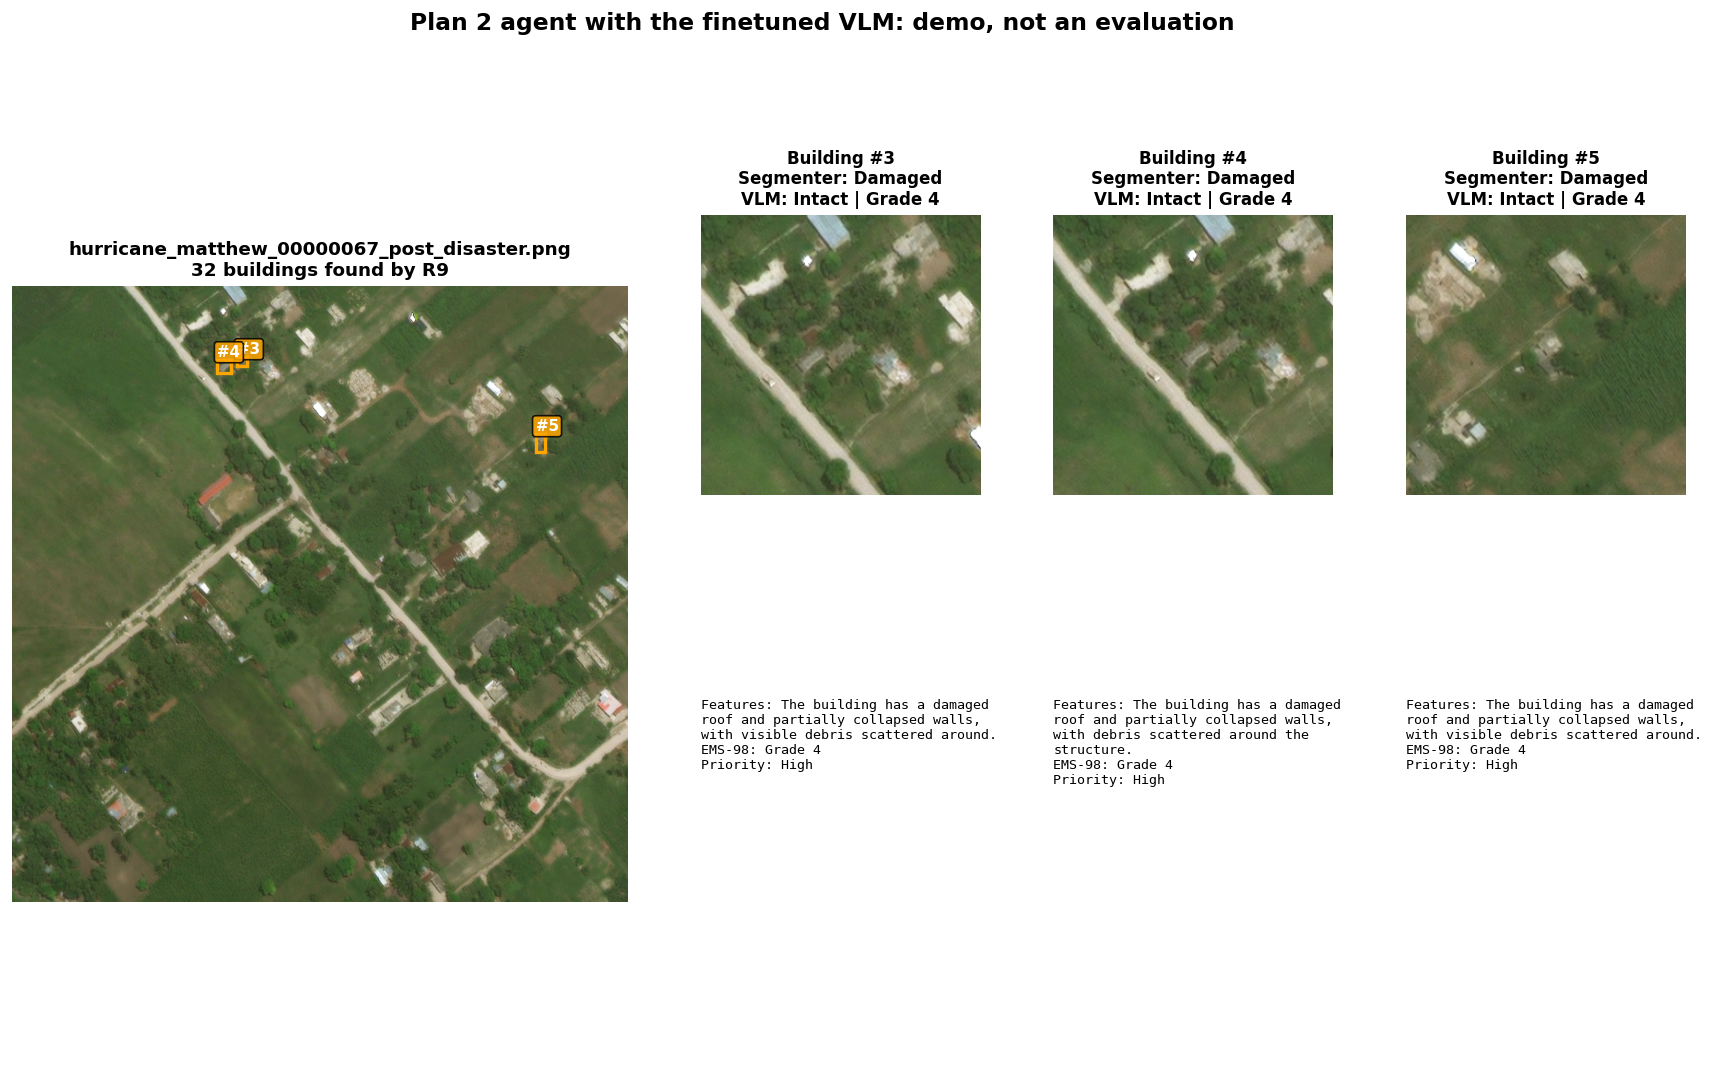

In [8]:
# ── Cell 8: Dashboard for the first demo tile with inspected buildings ──
shown = next((n for n in demo_names if reports[n]["inspections"]), demo_names[0])
rep = reports[shown]
image = cv2.cvtColor(cv2.imread(path_of[shown]), cv2.COLOR_BGR2RGB)
COLORS = {"Intact": "lime", "Damaged": "orange", "Destroyed": "red"}

fig = plt.figure(figsize=(18, 10), dpi=120)
gs = fig.add_gridspec(2, 4, width_ratios=[2.2, 1, 1, 1], height_ratios=[1, 0.8], hspace=0.3)
ax_main = fig.add_subplot(gs[:, 0])
ax_main.imshow(image)
ax_main.set_title(f"{shown}\n{rep['total_buildings']} buildings found by {SEG_MODEL}", fontsize=11, fontweight="bold")
ax_main.axis("off")
for r in rep["inspections"]:
    x1, y1, x2, y2 = r["bbox"]   # the segmenter's format: corners, not width and height
    c = COLORS.get(r["segmenter_class"], "white")
    ax_main.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, linewidth=2, edgecolor=c, facecolor="none"))
    ax_main.text(x1, max(0, y1 - 5), f"#{r['building_id']}", color="white", fontsize=9, fontweight="bold",
                 bbox=dict(boxstyle="round,pad=0.2", facecolor=c, alpha=0.85))

for idx, r in enumerate(rep["inspections"][:3]):
    ax_crop = fig.add_subplot(gs[0, idx + 1])
    ax_crop.imshow(r["crop_rgb"])
    ax_crop.set_title(f"Building #{r['building_id']}\nSegmenter: {r['segmenter_class']}\n"
                      f"VLM: {r['vlm_class'] or 'unparsed'} | {r['ems98_grade']}", fontsize=10, fontweight="bold")
    ax_crop.axis("off")
    ax_text = fig.add_subplot(gs[1, idx + 1])   # the VLM's inspection answer (in full in the crops CSV)
    shown_text = "\n".join(textwrap.fill(line, 38) for line in r["inspection_text"][:600].splitlines())
    ax_text.text(0, 1, shown_text, fontsize=8, va="top", family="monospace")
    ax_text.axis("off")

fig.suptitle(f"Plan 2 agent with the {RUN_NAME} VLM: {LABEL.lower()}", fontsize=14, fontweight="bold")
fig.savefig(OUT_DIR / f"{RUN_NAME}_demo_dashboard.png", bbox_inches="tight")
plt.show()

## 9. Summary of this run
Demo, not an evaluation: these values describe this run only and are not results.

Demo, not an evaluation. Agreement is between the VLM and the segmenter, not with the ground truth. Peak GPU memory is what PyTorch allocated in this run (U-Net and VLM).


,0
label,"Demo, not an evaluation"
run,finetuned
vlm,AbrarAlam/disasterm3-qwen2.5vl7b-mergedFP
segmenter,R9
tiles,10
buildings_found,363
buildings_inspected,30
vlm_agrees_with_segmenter,9
vlm_disagrees,21
vlm_class_unparsed,0


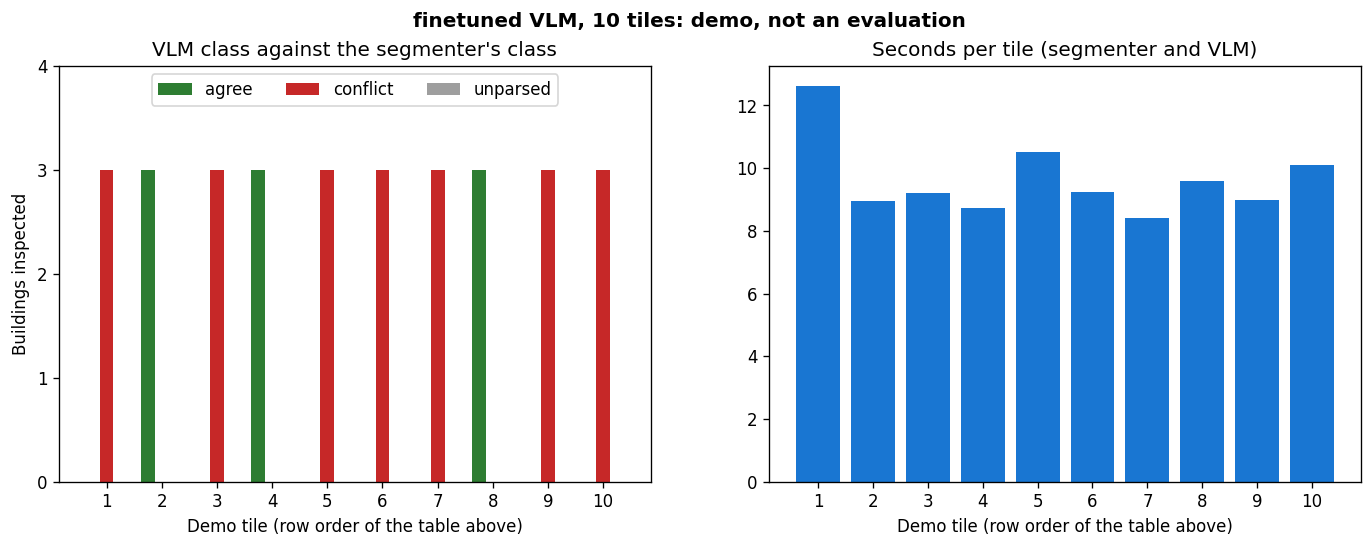

In [9]:
# ── Cell 9: This run's summary and a chart of its measured values (demo, not an evaluation) ──
parsed = int(df_tiles["agree"].sum() + df_tiles["conflict"].sum())
peak_gb = sum(torch.cuda.max_memory_allocated(i) for i in range(torch.cuda.device_count())) / 1024**3
summary = pd.DataFrame([{
    "label": LABEL, "run": RUN_NAME, "vlm": VLM_ID, "segmenter": SEG_MODEL,
    "tiles": len(df_tiles),
    "buildings_found": int(df_tiles["buildings"].sum()),
    "buildings_inspected": int(df_tiles["crops"].sum()),
    "vlm_agrees_with_segmenter": int(df_tiles["agree"].sum()),
    "vlm_disagrees": int(df_tiles["conflict"].sum()),
    "vlm_class_unparsed": int(df_tiles["unparsed"].sum()),
    "agreement_pct_of_parsed": round(100 * df_tiles["agree"].sum() / parsed, 1) if parsed else None,
    "mean_seconds_per_tile": round(df_tiles["seconds"].mean(), 2),
    "peak_gpu_memory_allocated_gb": round(peak_gb, 2),
}])
summary.to_csv(OUT_DIR / f"{RUN_NAME}_demo_summary.csv", index=False)
config = {"label": LABEL, "run": RUN_NAME, "vlm": VLM_ID, "segmenter": SEG_MODEL,
          "segmenter_checkpoint": str(seg_tool.checkpoint), "segmenter_input": seg_tool.input_mode,
          "tiles": demo_names, "seed": SEED, "max_crops": MAX_CROPS, "blob_area_px": [MIN_AREA, MAX_AREA],
          "decoding": "greedy", "quantization": "4-bit NF4", "class_prompt": CLASS_PROMPT,
          "inspection_prompt": inspection_prompt("<id>"),
          "versions": {"torch": torch.__version__, "transformers": transformers.__version__,
                       "segmentation-models-pytorch": _version("segmentation-models-pytorch"),
                       "albumentations": _version("albumentations"), "bitsandbytes": _version("bitsandbytes")}}
(OUT_DIR / f"{RUN_NAME}_demo_config.json").write_text(json.dumps(config, indent=1), encoding="utf-8")
print(f"{LABEL}. Agreement is between the VLM and the segmenter, not with the ground truth. "
      "Peak GPU memory is what PyTorch allocated in this run (U-Net and VLM).")
display(summary.T)

# Only values measured in this run, one group of bars per tile
x = np.arange(len(df_tiles))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5), dpi=120)
for offset, col, color in ((-0.25, "agree", "#2e7d32"), (0.0, "conflict", "#c62828"), (0.25, "unparsed", "#9e9e9e")):
    ax1.bar(x + offset, df_tiles[col], width=0.25, label=col, color=color)
ax1.set_title("VLM class against the segmenter's class")
ax1.set_ylabel("Buildings inspected")
ax1.yaxis.get_major_locator().set_params(integer=True)
ax1.set_ylim(0, MAX_CROPS + 1)             # room for the legend above the bars
ax1.legend(ncol=3, loc="upper center")
ax2.bar(x, df_tiles["seconds"], color="#1976d2")
ax2.set_title("Seconds per tile (segmenter and VLM)")
for ax in (ax1, ax2):
    ax.set_xticks(x, [str(i + 1) for i in x])
    ax.set_xlabel("Demo tile (row order of the table above)")
fig.suptitle(f"{RUN_NAME} VLM, {len(df_tiles)} tiles: {LABEL.lower()}", fontweight="bold")
fig.savefig(OUT_DIR / f"{RUN_NAME}_demo_chart.png", bbox_inches="tight")
plt.show()

## 10. Output files

In [10]:
# ── Cell 10: The output files ──
for p in sorted(OUT_DIR.iterdir()):
    print(f"  {p.name:<36} {p.stat().st_size / 1024:.1f} KB")

  finetuned_demo_chart.png             46.1 KB
  finetuned_demo_config.json           1.6 KB
  finetuned_demo_crops.csv             7.3 KB
  finetuned_demo_dashboard.png         1085.6 KB
  finetuned_demo_summary.csv           0.3 KB
  finetuned_demo_tiles.csv             0.7 KB
